In [1]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
#definir archivos e información de ubicación

from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"


sitios = {
    "Pozo Almonte": {
        "archivo": DATA_DIR / "pozo_almonte.csv",
        "latitud": -20.26753140414636,
        "longitud": -69.77801103385463,
        "altitud": 1037.0
    },
    "Pica": {
        "archivo": DATA_DIR / "pica.csv",
        "latitud": -20.49088377081416,
        "longitud": -69.33031816276088,
        "altitud": 1332.0
    },
    "Colchane": {
        "archivo": DATA_DIR / "colchane.csv",
        "latitud": -19.698839534259942,
        "longitud": -68.90281677246094,
        "altitud": 4161.0
    }
}

In [3]:
#cargar y unir lo 3 archivos
bases = []

for nombre_sitio, info in sitios.items():
    df = pd.read_csv(info["archivo"])

    df["Fecha/Hora"] = pd.to_datetime(df["Fecha/Hora"])
    df = df.sort_values("Fecha/Hora")

    df["sitio"] = nombre_sitio
    df["latitud"] = info["latitud"]
    df["longitud"] = info["longitud"]
    df["altitud"] = info["altitud"]

    bases.append(df)

df_total = pd.concat(bases, ignore_index=True)

df_total.head()

,Fecha/Hora,glb,dir,dif,sct,ghi,dirh,difh,dni,temp,vel,shadow,cloud,sitio,latitud,longitud,altitud
0,2004-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.64,1.31,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
1,2004-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.29,0.55,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
2,2004-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.59,0.69,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
3,2004-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.42,0.33,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
4,2004-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.06,0.47,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0


In [4]:
#verificar carga de datos
print("Cantidad de filas y columnas:")
print(df_total.shape)

print("\nCantidad de registros por sitio:")
print(df_total["sitio"].value_counts())

print("\nPeriodo disponible:")
print(df_total["Fecha/Hora"].min())
print(df_total["Fecha/Hora"].max())

print("\nColumnas:")
print(df_total.columns.tolist())

print("\nValores faltantes por columna:")
print(df_total.isna().sum())

Cantidad de filas y columnas:
(341856, 17)

Cantidad de registros por sitio:
sitio
Pozo Almonte    113952
Pica            113952
Colchane        113952
Name: count, dtype: int64

Periodo disponible:
2004-01-01 00:00:00
2016-12-30 23:00:00

Columnas:
['Fecha/Hora', 'glb', 'dir', 'dif', 'sct', 'ghi', 'dirh', 'difh', 'dni', 'temp', 'vel', 'shadow', 'cloud', 'sitio', 'latitud', 'longitud', 'altitud']

Valores faltantes por columna:
Fecha/Hora      0
glb           288
dir           288
dif           288
sct           288
ghi           288
dirh          288
difh          288
dni           288
temp            0
vel             0
shadow        288
cloud         288
sitio           0
latitud         0
longitud        0
altitud         0
dtype: int64


In [5]:
#revisar primeras y ultimas columnas
df_total.head(10)

,Fecha/Hora,glb,dir,dif,sct,ghi,dirh,difh,dni,temp,vel,shadow,cloud,sitio,latitud,longitud,altitud
0,2004-01-01 00:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,11.64,1.31,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
1,2004-01-01 01:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,10.29,0.55,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
2,2004-01-01 02:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,9.59,0.69,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
3,2004-01-01 03:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.42,0.33,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
4,2004-01-01 04:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.06,0.47,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
5,2004-01-01 05:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.50,0.53,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
6,2004-01-01 06:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.96,0.19,1.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
7,2004-01-01 07:00:00,82.90,52.34,29.29,1.27,176.08,145.88,30.20,723.03,12.35,0.58,0.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
8,2004-01-01 08:00:00,322.43,281.02,38.33,3.08,425.46,385.94,39.52,914.24,16.33,1.19,0.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0
9,2004-01-01 09:00:00,566.46,519.15,42.50,4.81,663.98,620.16,43.82,995.34,21.03,1.74,0.0,0.0,Pozo Almonte,-20.267531,-69.778011,1037.0


In [6]:
df_total.tail(10)

,Fecha/Hora,glb,dir,dif,sct,ghi,dirh,difh,dni,temp,vel,shadow,cloud,sitio,latitud,longitud,altitud
341846,2016-12-30 14:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.36,4.10,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341847,2016-12-30 15:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.70,4.31,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341848,2016-12-30 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.59,4.39,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341849,2016-12-30 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.44,2.86,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341850,2016-12-30 18:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.92,0.93,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341851,2016-12-30 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.86,0.95,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341852,2016-12-30 20:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.94,1.62,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341853,2016-12-30 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.08,2.22,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341854,2016-12-30 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-9.68,2.39,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0
341855,2016-12-30 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-9.68,2.60,NaN,NaN,Colchane,-19.69884,-68.902817,4161.0


In [7]:
print("Tamaño de la base:")
print(df_total.shape)

print("\nValores faltantes por columna:")
print(df_total.isna().sum())

print("\nRegistros por sitio:")
print(df_total["sitio"].value_counts())

Tamaño de la base:
(341856, 17)

Valores faltantes por columna:
Fecha/Hora      0
glb           288
dir           288
dif           288
sct           288
ghi           288
dirh          288
difh          288
dni           288
temp            0
vel             0
shadow        288
cloud         288
sitio           0
latitud         0
longitud        0
altitud         0
dtype: int64

Registros por sitio:
sitio
Pozo Almonte    113952
Pica            113952
Colchane        113952
Name: count, dtype: int64


In [8]:
#revisión de la estructura de los datos
print("Tamaño de la base:")
print(df_total.shape)

print("\nRegistros por sitio:")
print(df_total["sitio"].value_counts())

print("\nPeriodo por sitio:")
print(df_total.groupby("sitio")["Fecha/Hora"].agg(["min", "max", "count"]))

print("\nValores faltantes por columna:")
print(df_total.isna().sum())

Tamaño de la base:
(341856, 17)

Registros por sitio:
sitio
Pozo Almonte    113952
Pica            113952
Colchane        113952
Name: count, dtype: int64

Periodo por sitio:
                    min                 max   count
sitio                                              
Colchane     2004-01-01 2016-12-30 23:00:00  113952
Pica         2004-01-01 2016-12-30 23:00:00  113952
Pozo Almonte 2004-01-01 2016-12-30 23:00:00  113952

Valores faltantes por columna:
Fecha/Hora      0
glb           288
dir           288
dif           288
sct           288
ghi           288
dirh          288
difh          288
dni           288
temp            0
vel             0
shadow        288
cloud         288
sitio           0
latitud         0
longitud        0
altitud         0
dtype: int64


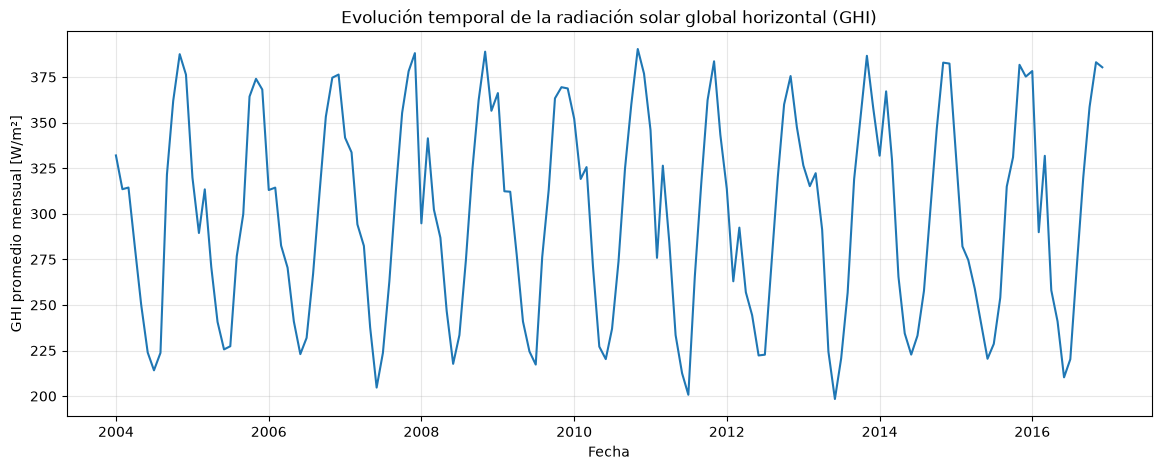

In [9]:
#evolución temporal de la radiación solar global horizontal.
# Crear promedio mensual general de GHI considerando todos los sitios
df_total["anio_mes"] = df_total["Fecha/Hora"].dt.to_period("M").dt.to_timestamp()

ghi_mensual_total = df_total.groupby("anio_mes")["ghi"].mean().reset_index()

# Gráfico de evolución temporal
plt.figure(figsize=(14,5))

plt.plot(
    ghi_mensual_total["anio_mes"],
    ghi_mensual_total["ghi"]
)

plt.title("Evolución temporal de la radiación solar global horizontal (GHI)")
plt.xlabel("Fecha")
plt.ylabel("GHI promedio mensual [W/m²]")
plt.grid(True, alpha=0.3)
plt.show()

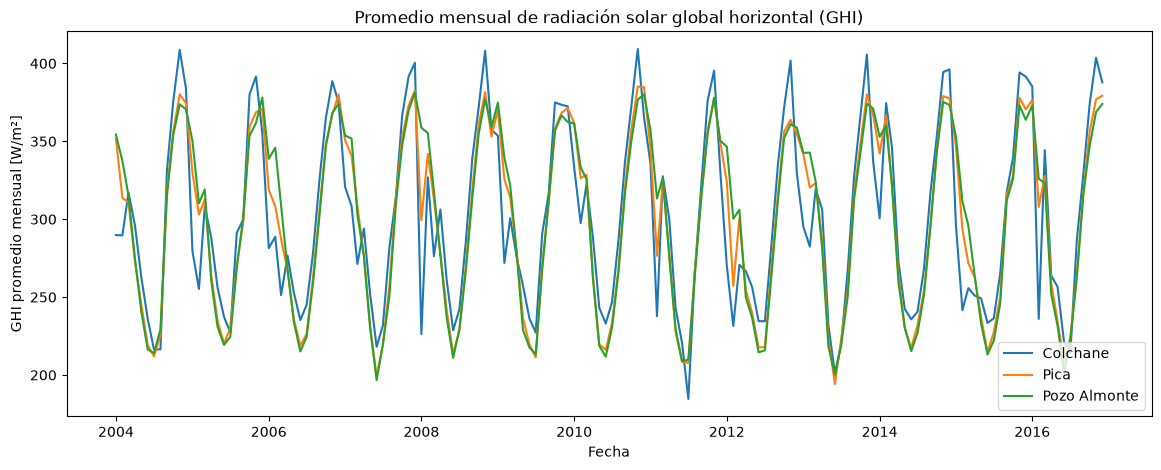

In [10]:
#promedio mensual de radiación por año
df_total["anio_mes"] = df_total["Fecha/Hora"].dt.to_period("M").dt.to_timestamp()

ghi_mensual = df_total.groupby(["anio_mes", "sitio"])["ghi"].mean().reset_index()

plt.figure(figsize=(14,5))

for sitio in ghi_mensual["sitio"].unique():
    datos = ghi_mensual[ghi_mensual["sitio"] == sitio]
    plt.plot(datos["anio_mes"], datos["ghi"], label=sitio)

plt.title("Promedio mensual de radiación solar global horizontal (GHI)")
plt.xlabel("Fecha")
plt.ylabel("GHI promedio mensual [W/m²]")
plt.legend()
plt.show()

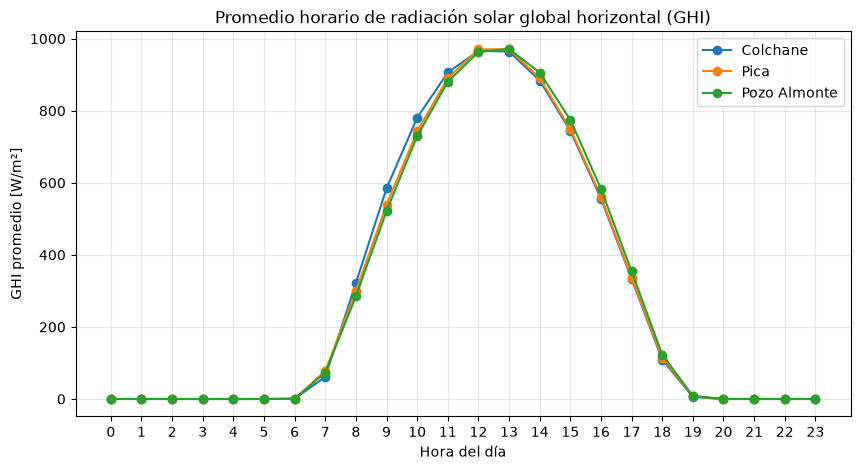

In [11]:
#promedio de radiación solar por hora
df_total["hora"] = df_total["Fecha/Hora"].dt.hour
ghi_horario = df_total.groupby(["hora", "sitio"])["ghi"].mean().reset_index()

plt.figure(figsize=(10,5))

for sitio in ghi_horario["sitio"].unique():
    datos = ghi_horario[ghi_horario["sitio"] == sitio]
    plt.plot(datos["hora"], datos["ghi"], marker="o", label=sitio)

plt.title("Promedio horario de radiación solar global horizontal (GHI)")
plt.xlabel("Hora del día")
plt.ylabel("GHI promedio [W/m²]")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<Figure size 800x500 with 0 Axes>

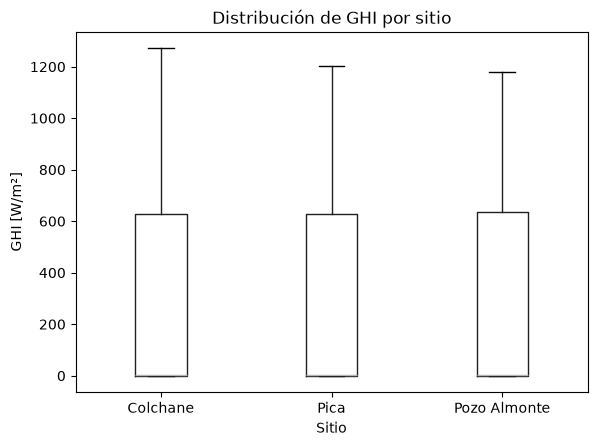

In [12]:
#distribución ghi por sitio (global)
plt.figure(figsize=(8,5))

df_total.boxplot(column="ghi", by="sitio", grid=False)

plt.title("Distribución de GHI por sitio")
plt.suptitle("")
plt.xlabel("Sitio")
plt.ylabel("GHI [W/m²]")
plt.show()

<Figure size 800x500 with 0 Axes>

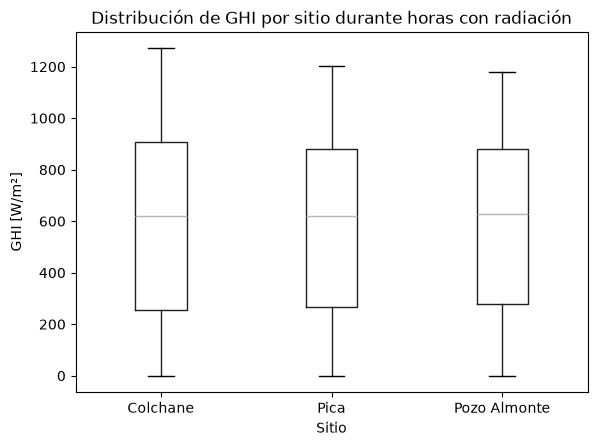

In [13]:
#ghi por sitio (solo horas solares)
df_dia = df_total[df_total["ghi"] > 0].copy()

plt.figure(figsize=(8,5))

df_dia.boxplot(column="ghi", by="sitio", grid=False)

plt.title("Distribución de GHI por sitio durante horas con radiación")
plt.suptitle("")
plt.xlabel("Sitio")
plt.ylabel("GHI [W/m²]")
plt.show()

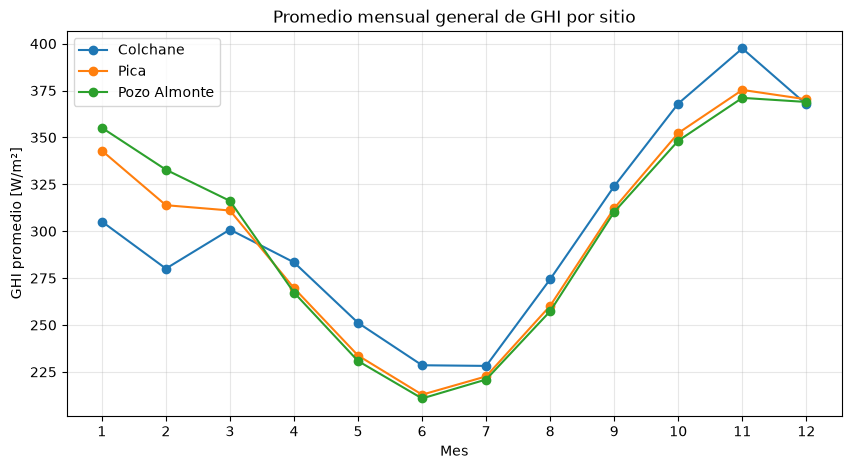

In [14]:
#promedio mensual por sitio
df_total["mes"] = df_total["Fecha/Hora"].dt.month

ghi_mes = df_total.groupby(["mes", "sitio"])["ghi"].mean().reset_index()

plt.figure(figsize=(10,5))

for sitio in ghi_mes["sitio"].unique():
    datos = ghi_mes[ghi_mes["sitio"] == sitio]
    plt.plot(datos["mes"], datos["ghi"], marker="o", label=sitio)

plt.title("Promedio mensual general de GHI por sitio")
plt.xlabel("Mes")
plt.ylabel("GHI promedio [W/m²]")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

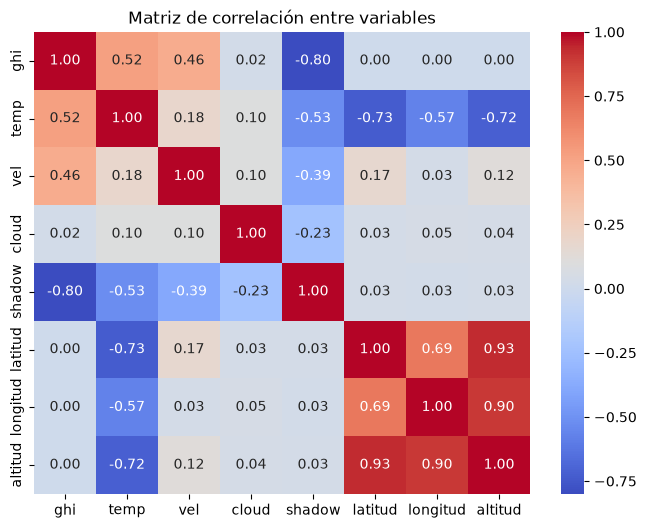

In [15]:
#matriz de correlación
import seaborn as sns

variables_corr = ["ghi", "temp", "vel", "cloud", "shadow", "latitud", "longitud", "altitud"]

corr = df_total[variables_corr].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación entre variables")
plt.show()

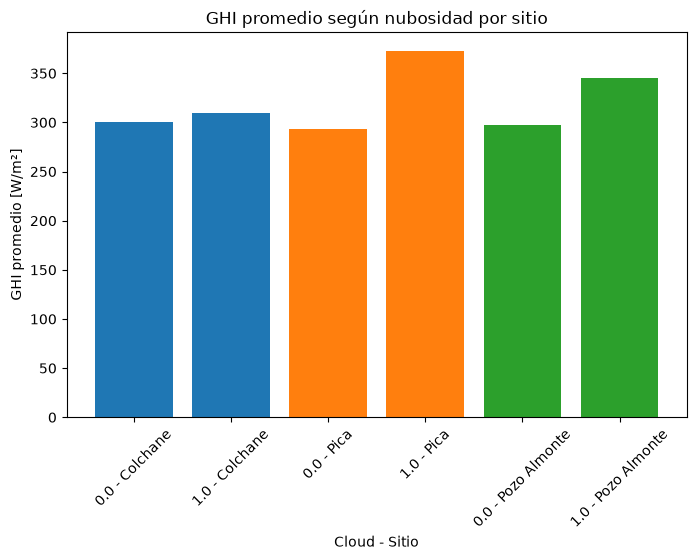

In [16]:
#ghi promedio según nubosidad y sitio
ghi_cloud = df_total.groupby(["cloud", "sitio"])["ghi"].mean().reset_index()

plt.figure(figsize=(8,5))

for sitio in ghi_cloud["sitio"].unique():
    datos = ghi_cloud[ghi_cloud["sitio"] == sitio]
    plt.bar(
        datos["cloud"].astype(str) + " - " + sitio,
        datos["ghi"]
    )

plt.title("GHI promedio según nubosidad por sitio")
plt.xlabel("Cloud - Sitio")
plt.ylabel("GHI promedio [W/m²]")
plt.xticks(rotation=45)
plt.show()

In [17]:
#revisar valores imposibles
df_total.groupby("sitio")["ghi"].describe()

,count,mean,std,min,25%,50%,75%,max
sitio,,,,,,,,
Colchane,113856.0,300.747458,400.153182,0.0,0.0,1.60,629.335,1271.02
Pica,113856.0,297.973472,385.900115,0.0,0.0,1.66,629.510,1201.34
Pozo Almonte,113856.0,298.940969,385.410295,0.0,0.0,2.20,637.465,1180.78


In [18]:
print("Mínimo GHI:", df_total["ghi"].min())
print("Máximo GHI:", df_total["ghi"].max())

Mínimo GHI: 0.0
Máximo GHI: 1271.02


In [19]:
#revisar temperatura y viento
df_total[["ghi", "temp", "vel"]].describe()

,ghi,temp,vel
count,341568.000000,341856.000000,341856.000000
mean,299.220633,12.851549,3.229404
std,390.548268,10.499995,2.341410
min,0.000000,-9.680000,0.000000
25%,0.000000,6.560000,1.480000
50%,1.840000,13.280000,2.700000
75%,632.160000,20.690000,4.290000
max,1271.020000,35.860000,15.850000


In [20]:
#revisar outliers
variables_revisar = ["ghi", "temp", "vel", "cloud", "shadow"]

print("Resumen estadístico:")
print(df_total[variables_revisar].describe())

print("\nMínimos por sitio:")
print(df_total.groupby("sitio")[variables_revisar].min())

print("\nMáximos por sitio:")
print(df_total.groupby("sitio")[variables_revisar].max())

Resumen estadístico:
                 ghi           temp            vel          cloud  \
count  341568.000000  341856.000000  341856.000000  341568.000000   
mean      299.220633      12.851549       3.229404       0.055081   
std       390.548268      10.499995       2.341410       0.228139   
min         0.000000      -9.680000       0.000000       0.000000   
25%         0.000000       6.560000       1.480000       0.000000   
50%         1.840000      13.280000       2.700000       0.000000   
75%       632.160000      20.690000       4.290000       0.000000   
max      1271.020000      35.860000      15.850000       1.000000   

              shadow  
count  341568.000000  
mean        0.522502  
std         0.499494  
min         0.000000  
25%         0.000000  
50%         1.000000  
75%         1.000000  
max         1.000000  

Mínimos por sitio:
              ghi  temp   vel  cloud  shadow
sitio                                       
Colchane      0.0 -9.68  0.01    0.0    